# SAC

面向连续动作空间的最大熵 Soft Actor-Critic 算法。

## 最大熵目标

SAC 在累计奖励之外加入策略熵，鼓励智能体保持探索：

$$
\pi^*=\arg\max_\pi
\mathbb{E}_{\tau\sim\pi}\left[
\sum_t\gamma^t\left(r(s_t,a_t)+\alpha\mathcal{H}(\pi(\cdot\mid s_t))\right)
\right].
$$

其中温度参数 $\alpha$ 控制奖励与熵之间的权衡。本实现会自动调整 $\alpha$，使策略熵接近目标熵。

## Actor：随机策略更新

软状态价值为

$$
V(s_t)=\mathbb{E}_{a_t\sim\pi_\theta}
\left[\min_{j=1,2}Q_{\omega_j}(s_t,a_t)
-\alpha\log\pi_\theta(a_t\mid s_t)\right].
$$

因此 Actor 最小化

$$
L_\pi(\theta)=\frac{1}{N}\sum_{i=1}^N
\left[
\alpha\log\pi_\theta(a_i\mid s_i)
-\min_{j=1,2}Q_{\omega_j}(s_i,a_i)
\right].
$$

实现采用重参数化采样，使梯度可以通过采样动作传回策略网络；随后用 `tanh` 将动作限制在环境允许的范围内。

## Critic：双 Q 网络

两个 Critic 都拟合软 TD 目标

$$
y_t=r_t+\gamma(1-d_t)\left[
\min_{j=1,2}Q_{\bar\omega_j}(s_{t+1},a_{t+1})
-\alpha\log\pi_\theta(a_{t+1}\mid s_{t+1})
\right],
$$

其中 $a_{t+1}\sim\pi_\theta(\cdot\mid s_{t+1})$，$\bar\omega_j$ 表示目标网络参数。每个 Critic 的损失为

$$
L_Q(\omega_j)=\mathbb{E}\left[
\left(Q_{\omega_j}(s_t,a_t)-y_t\right)^2
\right].
$$

### 关键稳定化技巧

- **Clipped Double Q**：Actor 和 TD 目标都取两个 Q 估计中的较小值，以缓解价值过高估计。
- **目标网络**：使用两个目标 Critic 计算 TD 目标，并通过软更新缓慢跟随在线 Critic。
- **自动温度调节**：学习 $lpha$，使策略的探索程度接近设定的目标熵。
- **经验回放**：从回放缓冲区随机采样小批量转移，提高数据利用率并减弱样本相关性。

## 代码实现

### 导入依赖

In [1]:
import random
import gym
import numpy as np
from tqdm import tqdm
import torch
import torch.nn.functional as F
from torch.distributions import Normal
import matplotlib.pyplot as plt
import rl_utils
np.bool8 = np.bool

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/var/folders/qn/n_1307qj75q0sdzx36m_mn040000gn/T/ipykernel_63304/3210283112.py:10: DeprecationWarning: `np.bool` is a deprecated alias for the builtin `bool`. To silence this warning, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
Deprecated in NumPy 1.20; for more details and guidance: https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations
  np.bool8 = np.bool


### 策略网络与价值网络

策略网络输出高斯分布的均值和标准差，通过重参数化采样得到动作；两个 Critic 分别输入状态与动作并输出 Q 值。

In [2]:
class PolicyNetContinuous(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim, action_bound):
        super(PolicyNetContinuous, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc_mu = torch.nn.Linear(hidden_dim, action_dim)
        self.fc_std = torch.nn.Linear(hidden_dim, action_dim)
        self.action_bound = action_bound

    def forward(self, obs):
        x = F.relu(self.fc1(obs))
        # 计算输出分布
        mu = self.fc_mu(x)
        std = F.softplus(self.fc_std(x))
        dist = Normal(mu, std)
        # 重参数化采样
        normal_sample = dist.rsample() # Pi(a|s)
        log_prob = dist.log_prob(normal_sample) # log(Pi(a|s))
        action = torch.tanh(normal_sample) # 限制动作在[-1,1]之间
        # 修正概率分布
        log_prob = log_prob - torch.log(1 - torch.tanh(action).pow(2) + 1e-7)
        action = action * self.action_bound
        return action, log_prob
    
class CriticNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(CriticNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim+action_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, hidden_dim)
        self.fc_out = torch.nn.Linear(hidden_dim, 1)
    
    def forward(self, obs, a):
        x = torch.concatenate([obs, a], dim=1)
        x = F.relu(self.fc1(x))
        x = F.relu((self.fc2(x)))
        return self.fc_out(x)

### SAC 智能体

`SACAgent` 依次更新两个 Critic、Actor 和温度参数，最后对两个目标 Critic 进行软更新。

In [3]:
class SACAgent:
    def __init__(self, state_dim, hidden_dim, action_dim, action_bound, 
                 actor_lr, critic_lr, alpha_lr, target_entropy, tau, gamma, 
                 device):
        self.actor = PolicyNetContinuous(state_dim, hidden_dim, action_dim, action_bound)
        self.critic_1 = CriticNet(state_dim, hidden_dim, action_dim).to(device)
        self.critic_2 = CriticNet(state_dim, hidden_dim, action_dim).to(device)
        self.target_1 = CriticNet(state_dim, hidden_dim, action_dim).to(device)
        self.target_2 = CriticNet(state_dim, hidden_dim, action_dim).to(device)

        # 令目标Q网络的初始参数和Q网络一样
        self.target_1.load_state_dict(self.critic_1.state_dict())
        self.target_2.load_state_dict(self.critic_2.state_dict())
        self.actor_optimizer = torch.optim.Adam(self.actor.parameters(),
                                                lr=actor_lr)
        self.critic_1_optimizer = torch.optim.Adam(self.critic_1.parameters(),
                                                   lr=critic_lr)
        self.critic_2_optimizer = torch.optim.Adam(self.critic_2.parameters(),
                                                   lr=critic_lr)       
        # 自动温度调整机制， 调节所需熵的程度
        self.log_alpha = torch.tensor(np.log(0.01), dtype=torch.float)
        self.log_alpha.requires_grad = True  # 可以对alpha求梯度
        self.log_alpha_optimizer = torch.optim.Adam([self.log_alpha], lr=alpha_lr)
        self.target_entropy = target_entropy  # 目标熵的大小
        self.gamma = gamma
        self.tau = tau
        self.device = device

    def take_action(self, obs):
        obs = torch.tensor([obs], dtype=torch.float).to(self.device)
        action = self.actor(obs)[0]
        return [action.item()]
    
    def update(self, transition_dict):
        states = torch.tensor(transition_dict['states'],
                              dtype=torch.float).to(self.device)
        actions = torch.tensor(transition_dict['actions'],
                               dtype=torch.float).view(-1, 1).to(self.device)
        rewards = torch.tensor(transition_dict['rewards'],
                               dtype=torch.float).view(-1, 1).to(self.device)
        next_states = torch.tensor(transition_dict['next_states'],
                                   dtype=torch.float).to(self.device)
        dones = torch.tensor(transition_dict['dones'],
                             dtype=torch.float).view(-1, 1).to(self.device)
        # trick 
        rewards = (rewards + 8.0) / 8.0

        # 更新Q网络
        td_target = self.calc_target(rewards, next_states, dones) #用目标网络计算V(s')
        critic_1_loss = torch.mean(F.mse_loss(self.critic_1(states, actions), td_target.detach()))
        critic_2_loss = torch.mean(F.mse_loss(self.critic_2(states, actions), td_target.detach()))
        self.critic_1_optimizer.zero_grad()
        critic_1_loss.backward()
        self.critic_1_optimizer.step()
        self.critic_2_optimizer.zero_grad()
        critic_2_loss.backward()
        self.critic_2_optimizer.step()
        # 更新策略
        rsample_action, log_prob = self.actor(states)
        entropy = -log_prob
        q_value_1 = self.critic_1(states, rsample_action)
        q_value_2 = self.critic_2(states, rsample_action)
        actor_loss = torch.mean(-self.log_alpha.exp() * entropy - torch.min(q_value_1, q_value_2))
        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()
        # 更新alpha
        alpha_loss = torch.mean(
            (entropy - self.target_entropy).detach() * self.log_alpha.exp())
        self.log_alpha_optimizer.zero_grad()
        alpha_loss.backward()
        self.log_alpha_optimizer.step()
        # 更新目标网络, soft update
        self.soft_update(self.critic_1, self.target_1)
        self.soft_update(self.critic_2, self.target_2)        
    
    def calc_target(self, reward, next_obs, dones):
        next_actions, log_prob = self.actor(next_obs)
        entropy = -log_prob # -log(Pi(a'|s'))
        q1_value = self.target_1(next_obs, next_actions) # Q1'(s',a')
        q2_value = self.target_2(next_obs, next_actions) # Q2'(s',a')
        q_value = torch.min(q1_value, q2_value)
        next_value = q_value + self.log_alpha.exp() * entropy
        td_target = reward + self.gamma * next_value * (1 - dones)
        return td_target

    def soft_update(self, net, target_net):
        for param_target, param in zip(target_net.parameters(),
                                       net.parameters()):
            param_target.data.copy_(param_target.data * (1.0 - self.tau) +
                                    param.data * self.tau)



In [4]:
env_name = 'Pendulum-v1'
env = gym.make(env_name)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]
action_bound = env.action_space.high[0]  # 动作最大值
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
env.seed(0)

actor_lr = 3e-4
critic_lr = 3e-3
alpha_lr = 3e-4
num_episodes = 100
hidden_dim = 128
gamma = 0.99
tau = 0.005  # 软更新参数
buffer_size = 100000
minimal_size = 1000
batch_size = 64
target_entropy = -env.action_space.shape[0]
device = torch.device("cuda") if torch.cuda.is_available() else torch.device(
    "cpu")

replay_buffer = rl_utils.ReplayBuffer(buffer_size)
agent = SACAgent(state_dim, hidden_dim, action_dim, action_bound,
                      actor_lr, critic_lr, alpha_lr, target_entropy, tau,
                      gamma, device)

return_list = rl_utils.train_off_policy_agent(env, agent, num_episodes,
                                              replay_buffer, minimal_size,
                                              batch_size)


/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:329: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:268: DeprecationWarning: WARN: Function `env.seed(seed)` is marked as deprecated and will be removed in the future. Please use `env.reset(seed=seed)` instead.
  deprecation(
Iteration 0:   0%|          | 0/10 [00:00<?, ?it/s]/var/folders/qn/n_1307qj75q0sdzx36m_mn040000gn/T/ipykernel_63304/4063686246.py:

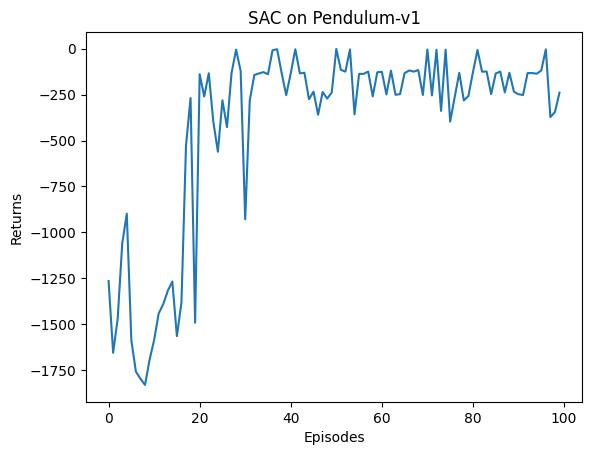

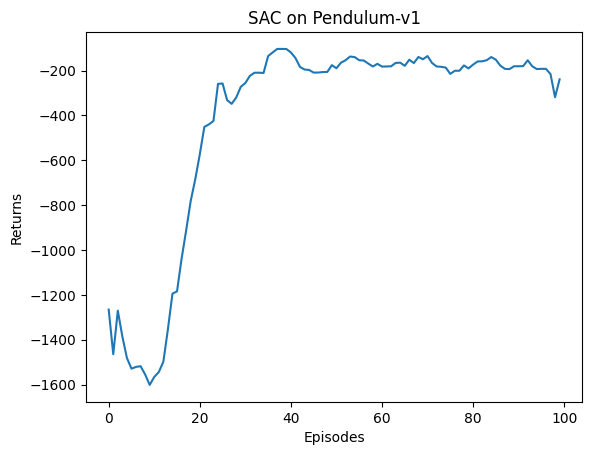

In [5]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('SAC on {}'.format(env_name))
plt.show()

mv_return = rl_utils.moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('SAC on {}'.format(env_name))
plt.show()